# Method of Mean Weighted Residuals

**Seong Cho** · ACME Volume 4, Lab 15

**Lab objective:** We introduce the method of mean weighted residuals (MWR) and use it to derive a pseudospectral method. This method will then be used to solve several boundary value problems.

<sub>Lab specification from the *Volume 4* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import barycentric_interpolate
import scipy.linalg as la
from scipy.optimize import root
from mpl_toolkits.mplot3d import Axes3D

In [2]:
# [compat] was %matplotlib notebook, which doesn't render in an executed notebook or on GitHub
%matplotlib inline

## The Method of Mean Weighted Residuals

For a linear differential equation $Lu = f$ on $[-1, 1]$ with boundary conditions, approximate the solution by a combination of $N + 1$ basis functions, $u(x) \approx u_N(x) = \sum_{i=0}^N a_i \phi_i(x)$, and choose the $a_i$ to minimize the *residual* $R(x, u_N) = Lu_N - f$ (which is $0$ for the true solution). Different ways of minimizing the residual, and different bases, give many more specific methods.

## The Pseudospectral Method

The *pseudospectral* (collocation) method forces $R(x, u_N) = 0$ at $N + 1$ *collocation points*. Here the basis is the Chebyshev polynomials,

$$T_0(x) = 1, \qquad T_1(x) = x, \qquad T_{n+1}(x) = 2xT_n(x) - T_{n-1}(x),$$

and the collocation points are the Gauss-Lobatto points $x_i = \cos(\pi i/N)$, $i = 0, \ldots, N$. Since $u_N$ is a polynomial of order $N$, it is described equivalently by its Chebyshev coefficients or by its values at the collocation points, and the two forms satisfy

$$MA = F \tag{15.1}$$

and

$$LU = F, \tag{15.2}$$

where $U_i = u(x_i)$, $A_i = a_i$, $F_i = f(x_i)$, $L_{ij} = (LC_j(x))|_{x = x_i}$ and $M_{ij} = (L\phi_j(x))|_{x = x_i}$. The *cardinal functions* $C_j$ are the polynomials of least degree with $C_j(x_i) = 1$ if $i = j$ and $0$ otherwise, so $u_N(x) = \sum_j u_N(x_j)C_j(x)$.

When $L = d/dx$, the matrix in (15.2) is the *differentiation matrix* $D$:

$$D_{ij} = \frac{dC_j}{dx}(x_i) = \begin{cases} (1 + 2N^2)/6 & i = j = 0, \\ -(1 + 2N^2)/6 & i = j = N, \\ -x_j/[2(1 - x_j^2)] & i = j, \ 0 < j < N, \\ (-1)^{i+j}\alpha_i/[\alpha_j(x_i - x_j)] & i \neq j, \end{cases}$$

where $\alpha_0 = \alpha_N = 2$ and $\alpha_j = 1$ otherwise. It can be used to piece together the matrix $L$ for more complicated operators. The spec gives a stable, vectorized function to build it:

In [3]:
def cheb(N):
    """Returns the (N+1)x(N+1) cardinal function differentiation matrix D 
    and the N+1 Chebyshev nodes.
    """
    x =  np.cos((np.pi/N)*np.linspace(0,N,N+1))
    x.shape = (N+1,1)
    lin = np.linspace(0,N,N+1)
    lin.shape = (N+1,1)
    
    c = np.ones((N+1,1))
    c[0], c[-1] = 2., 2.
    c = c*(-1.)**lin
    X = x*np.ones(N+1) # broadcast along 2nd dimension (columns)
    
    dX = X - X.T
    
    D = (c*(1./c).T)/(dX + np.eye(N+1))
    D  = D - np.diag(np.sum(D.T,axis=0))
    x.shape = (N+1,)
    # Here we return the differentiation matrix and the Chebyshev points,
    # numbered from x_0 = 1 to x_N = -1
    return D, x

## Problem 1: Using the differentiation matrix

> **Problem 1.** Use the differentiation matrix to numerically approximate the derivative of $u(x) = e^{x}\cos(6x)$ on a grid of $N$ Chebychev points where $N = 6, 8,$ and $10$. (Use the linear system $DU \approx U'$.) Then use barycentric interpolation `scipy.interpolate.barycentric_interpolate` to approximate $u'$ on a grid of 100 evenly spaced points.
>
> Graphically compare your approximation to the exact derivative. Note that this convergence would not be occurring if the collocation points were equally spaced.

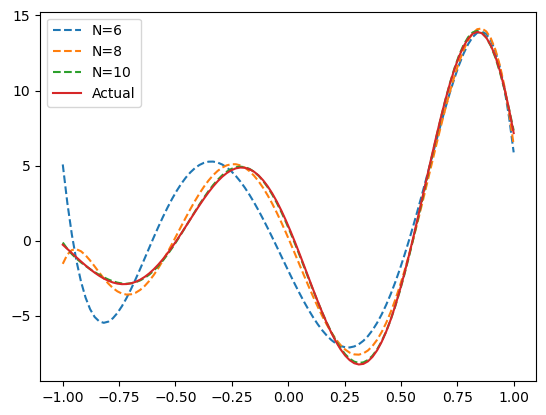

In [4]:
u = lambda x: np.exp(x) * np.cos(6*x)
u_prime = lambda x: np.exp(x) * np.cos(6*x) - 6*np.exp(x)*np.sin(6*x)
domain = np.linspace(-1, 1, 100)
fig = plt.figure()
for N in [6, 8, 10]:
    D, x = cheb(N)
    U = u(x)
    Uprime = barycentric_interpolate(x, D@U, domain)
    plt.plot(domain, Uprime, "--", label="N=" + str(N))
plt.plot(domain, u_prime(domain), label="Actual")
plt.legend()
plt.show()

## Boundary value problems

On the grid $\{x_i\}$, $U'' \approx D^2U$, so the BVP $u'' = f(x)$, $x \in [-1, 1]$, $u(-1) = u(1) = 0$ is discretized by

$$D^2U = F, \tag{15.3}$$

where $F = [f(x_0), \ldots, f(x_N)]^T$. The Dirichlet conditions are imposed by replacing the first and last equations of (15.3) with $U[0] = U[N] = 0$:

```python
D, x = cheb(N)
D2 = np.dot(D, D)
D2[0,:], D2[-1,:] = 0, 0
D2[0,0], D2[-1,-1] = 1, 1
F[0], F[-1] = 0, 0
```

## Problem 2: A linear BVP

> **Problem 2.** Use the pseudospectral method to solve the boundary value problem
>
> $$\begin{aligned} &u'' = e^{2x}, \quad x \in (-1,1), \\ &u(-1) = 0, \quad u(1) = 0. \end{aligned}$$
>
> Use $N = 8$ in the `cheb(N)` method and use barycentric interpolation to approximate $u$ on 100 evenly spaced points. Compare your numerical solution with the exact solution:
>
> $$u(x) = \frac{-\cosh(2) - \sinh(2)x + e^{2x}}{4}.$$

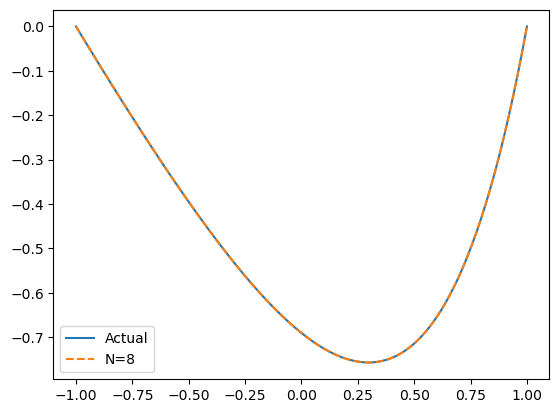

In [5]:
f = lambda x: np.exp(2*x)
u = lambda x: (-np.cosh(2) - np.sinh(2)*x + np.exp(2*x)) / 4
domain = np.linspace(-1, 1, 100)
N = 8
D, x = cheb(N)
F = f(x)
D2 = np.dot(D, D)
D2[0,:], D2[-1,:] = 0, 0
D2[0,0], D2[-1,-1] = 1, 1
F[0], F[-1] = 0, 0
U = la.solve(D2, F)
U = barycentric_interpolate(x, U, domain)
fig = plt.figure()
plt.plot(domain, u(domain), label="Actual")
plt.plot(domain, U, '--', label="N=8")
plt.legend()
plt.show()

In [6]:
# Check: maximum error against the exact solution
np.max(np.abs(U - u(domain)))

np.float64(3.732928893440679e-06)

## Problem 3: Nonzero boundary conditions

> **Problem 3.** Use the pseudospectral method to solve the boundary value problem
>
> $$\begin{aligned} &u'' + u' = e^{3x}, \quad x \in (-1,1), \\ &u(-1) = 2, \quad u(1) = -1. \end{aligned}$$
>
> Use $N = 8$ in the `cheb(N)` method and use barycentric interpolation to approximate $u$ on 100 evenly spaced points.

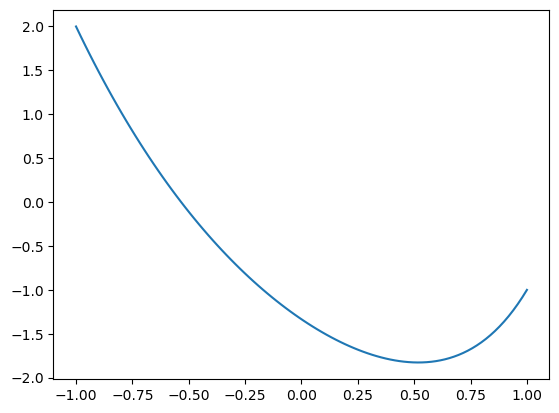

In [7]:
f = lambda x: np.exp(3*x)
N = 8
domain = np.linspace(-1, 1, 100)
D, x = cheb(N)
F = f(x)
D2 = np.dot(D, D)
M = D2 + D
M[0,:], M[-1,:] = 0,0
M[0,0], M[-1,-1] = 1,1
F[0], F[-1] = -1, 2
U = la.solve(M, F)
U = barycentric_interpolate(x, U, domain)
fig = plt.figure()
plt.plot(domain, U)
plt.show()

## Problem 4: A nonlinear BVP

When the ODE is nonlinear, the discretization is a nonlinear system of equations, solved with Newton's method (`scipy.optimize.root`): define a function whose root is the discretized equation with the boundary rows set correctly, and pass it an initial guess the same size as the `cheb(N)` output.

> **Problem 4.** Use the pseudospectral method to solve the boundary value problem
>
> $$\begin{aligned} &u'' = \lambda\sinh(\lambda u), \quad x \in (0,1), \\ &u(0) = 0, \quad u(1) = 1 \end{aligned}$$
>
> for several values of $\lambda$: $\lambda = 4, 8, 12$. Begin by transforming this BVP onto the domain $-1 < x < 1$. Use $N = 20$ in the `cheb(N)` method and use barycentric interpolation to approximate $u$ on 100 evenly spaced points.

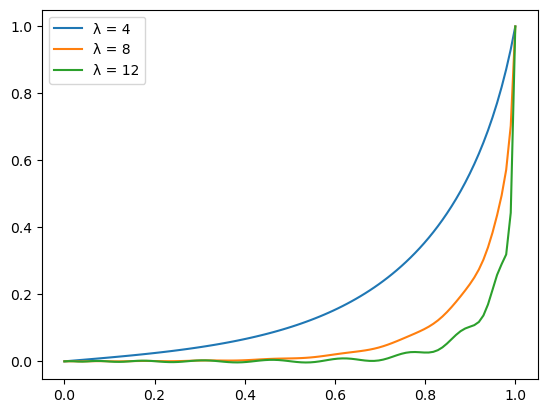

In [8]:
domain = np.linspace(-1, 1, 100)
domain2 = np.linspace(0, 1, 100)
fig = plt.figure()
for l in [4, 8, 12]:
    N = 20
    D, x = cheb(N)
    D2 = np.dot(D, D)
    def F(U):
        LHS = 4*D2@U
        RHS = l*np.sinh(l*U)
        bc1 = U[0] - 1
        bc2 = U[-1]
        return np.hstack([bc1, (LHS-RHS)[1:-1], bc2])
    solution = root(F, np.ones(len(x))).x
    U = barycentric_interpolate(x, solution, domain)
    plt.plot(domain2, U, label="λ = " + str(l))
plt.legend()
plt.show()

## Minimizing the Area of a Surface of Revolution

A surface of revolution that minimizes its area is an example of a *minimal surface*; soap bubbles and soap films on a wire frame are famous examples. For $y(x)$ on $[-1, 1]$ with $y(-1) = a$, $y(1) = b$, the area of the surface obtained by revolving the graph about the $x$-axis is

$$T[y(x)] = \int_{-1}^1 2\pi y(x)\sqrt{1 + (y'(x))^2}\, dx.$$

Minimizing this functional is a problem from the calculus of variations. A necessary condition is the Euler-Lagrange equation $L_y - \frac{d}{dx}L_{y'} = 0$ with $L(x, y, y') = 2\pi y\sqrt{1 + (y')^2}$, which simplifies to

$$yy'' - (y')^2 - 1 = 0.$$

The pseudospectral discretization is the nonlinear system $Y \cdot (D^2Y) - (DY) \cdot (DY) = I$, where $I$ is a vector of ones.

## Problem 5: A minimal surface of revolution

> **Problem 5.** Find the function $y(x)$ that satisfies $y(-1) = 1$, $y(1) = 7$, and whose surface of revolution (about the $x$-axis) minimizes surface area. Compute the surface area, and plot the surface.
>
> Use $N = 50$ in the `cheb(N)` method and use barycentric interpolation to approximate $u$ on 100 evenly spaced points.

*Not completed.* (The surface area is not computed; the cell below finds $y(x)$ and plots the surface.)

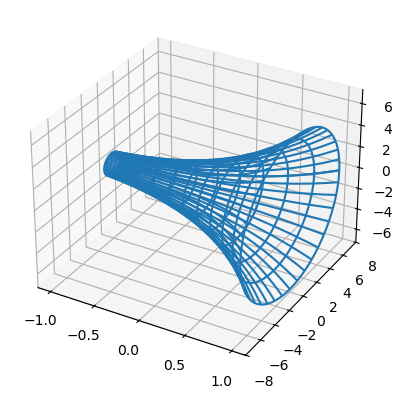

In [9]:
N = 50
domain = np.linspace(-1, 1, 100)
D, x = cheb(N)
D2 = np.dot(D, D)
def F(Y):
    RHS = Y*(D2@Y) - (D@Y)*(D@Y)
    LHS = np.ones(len(Y))
    bc1 = Y[0] - 7
    bc2 = Y[-1] - 1
    return np.hstack([bc1, (RHS-LHS)[1:-1], bc2])
solution = root(F, 3*np.ones(len(x))).x
U = barycentric_interpolate(x, solution, domain)

x = np.linspace(-1, 1, 100)
theta = np.linspace(0,2*np.pi,401)
X, T = np.meshgrid(x, theta)
Y, Z = U*np.cos(T), U*np.sin(T)
fig = plt.figure()
ax = fig.add_subplot(111,projection="3d")
ax.plot_wireframe(X, Y, Z, rstride=10, cstride=10)
plt.show()